In [1]:
import sys
sys.path.append("../../RL Policy Sparsification")

In [2]:
import gym, warnings, torch, os, gc
import pandas as pd
from tqdm.notebook import tqdm
from models import PolicyNet, SparsePolicyNet
from utils import (
    low_rank_approximate_policy, 
    plot_result_dataframe, 
    run_evaluation
)
warnings.filterwarnings("ignore")
os.environ["ENV_SEED"] = "3407"
os.environ["DEVICE"] = "cuda" if torch.cuda.is_available() else "cpu"
RENDER_MODE_ON_EVAL = None

In [3]:
env_name = "Acrobot-v1"
env = gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL)

#model hyper-parameters
observation_space = env.observation_space._shape[0]
action_space = env.action_space.n
hidden_size = 128
ranks = range(5, 30)

results_dir = "../decomposition_results"
os.makedirs(results_dir, exist_ok=True)

# Low Rank Approximation of DQN Policies

## Low Rank Approximation for Dense Policy

#### **Evaluate Dense Policy**

In [4]:
dense_weights_filename = f"{env_name}_DQN_dense_agent.pth.tar"
dense_policy_agent = PolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
dense_policy_agent.load_state_dict(torch.load(os.path.join("../params", dense_weights_filename), map_location=os.getenv("DEVICE")))

run_evaluation(gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), dense_policy_agent, verbose=True)

Evaluation reward of policy: -74.0
Average entropy of policy: 0.0068467


(-74.0, 0.006846688789129257)

#### **Evaluate Low Rank Approximated Dense Policy**

  0%|          | 0/25 [00:00<?, ?it/s]

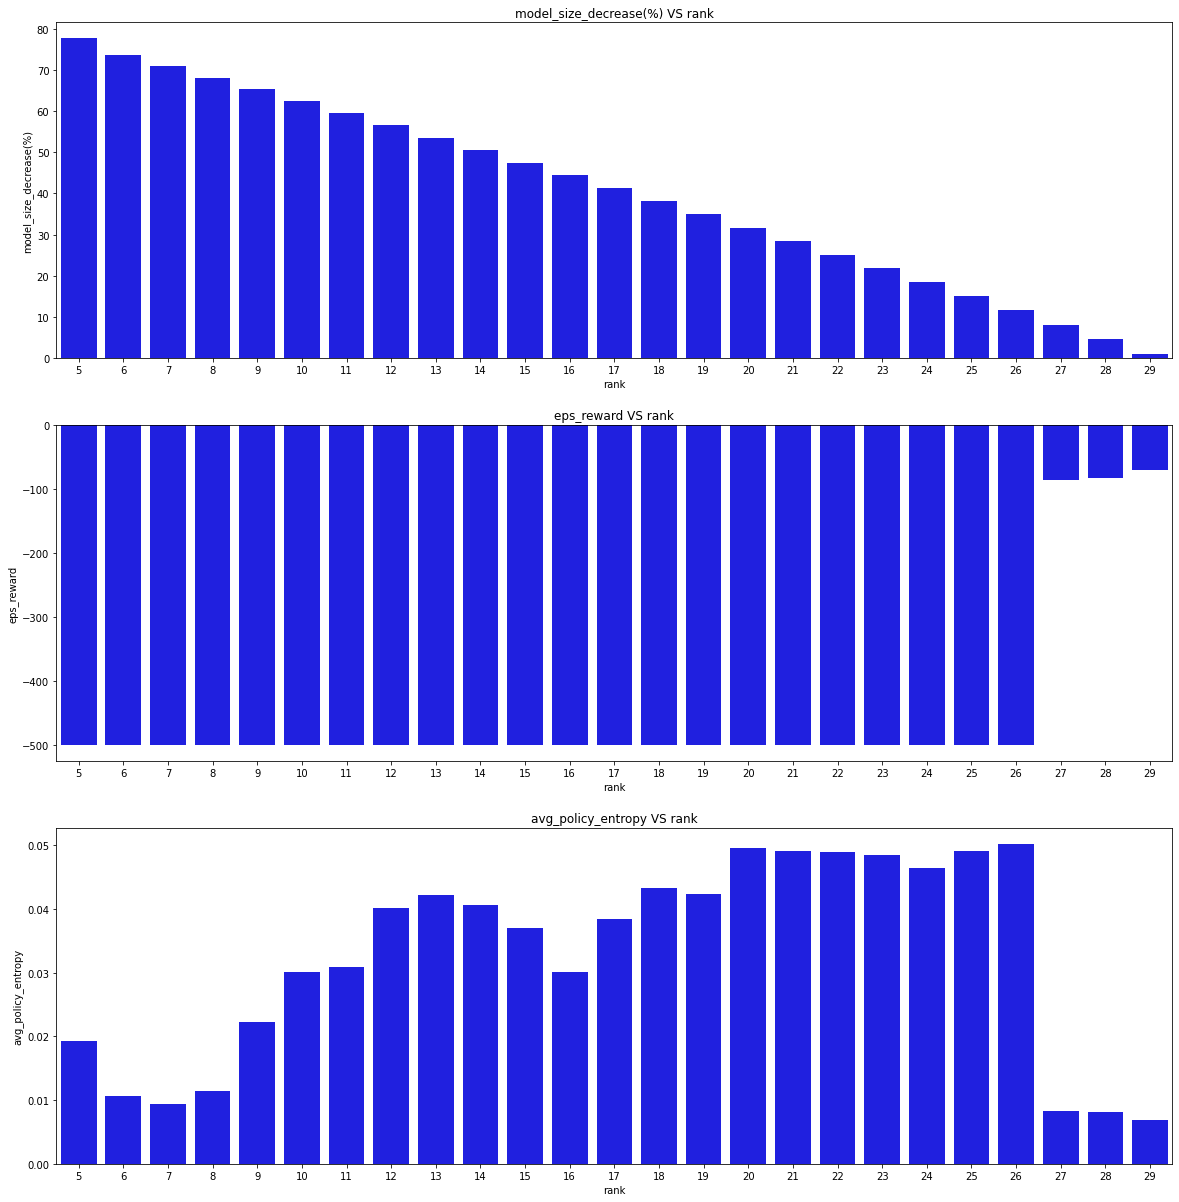

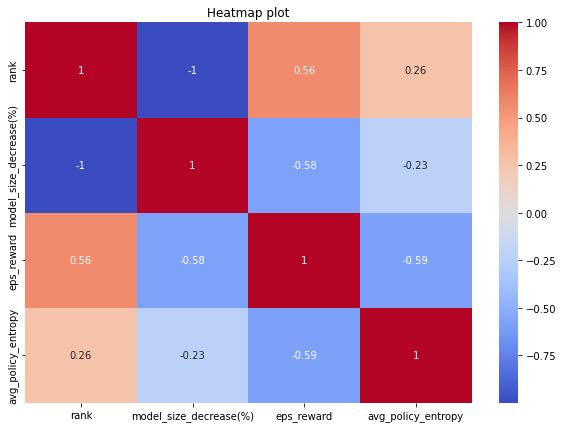

In [5]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []

for rank in tqdm(ranks):
    lra_dense_policy_agent, p = low_rank_approximate_policy(dense_policy_agent, rank)
    eps_reward, avg_policy_entropy = run_evaluation(
        gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), lra_dense_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    
result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank", plot_type="bar", with_heatmap=True)
result.to_csv(os.path.join(results_dir, f"{env_name}_DQN_dense_policy_decomposition.csv"), index=False)

## Low Rank Approximation for Sparse Policy

#### **Evaluate Sparse Policy**

In [6]:
sparse_weights_filename = f"{env_name}_DQN_sparse_agent.pth.tar"
sparse_policy_agent = SparsePolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
sparse_policy_agent.load_state_dict(torch.load(os.path.join("../params", sparse_weights_filename), map_location=os.getenv("DEVICE")))

result_df = run_evaluation(gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), sparse_policy_agent, verbose=True)

Evaluation reward of policy: -71.0
Average entropy of policy: 0.0070181


#### **Evaluate Low Rank Approximated Sparse Policy**

  0%|          | 0/25 [00:00<?, ?it/s]

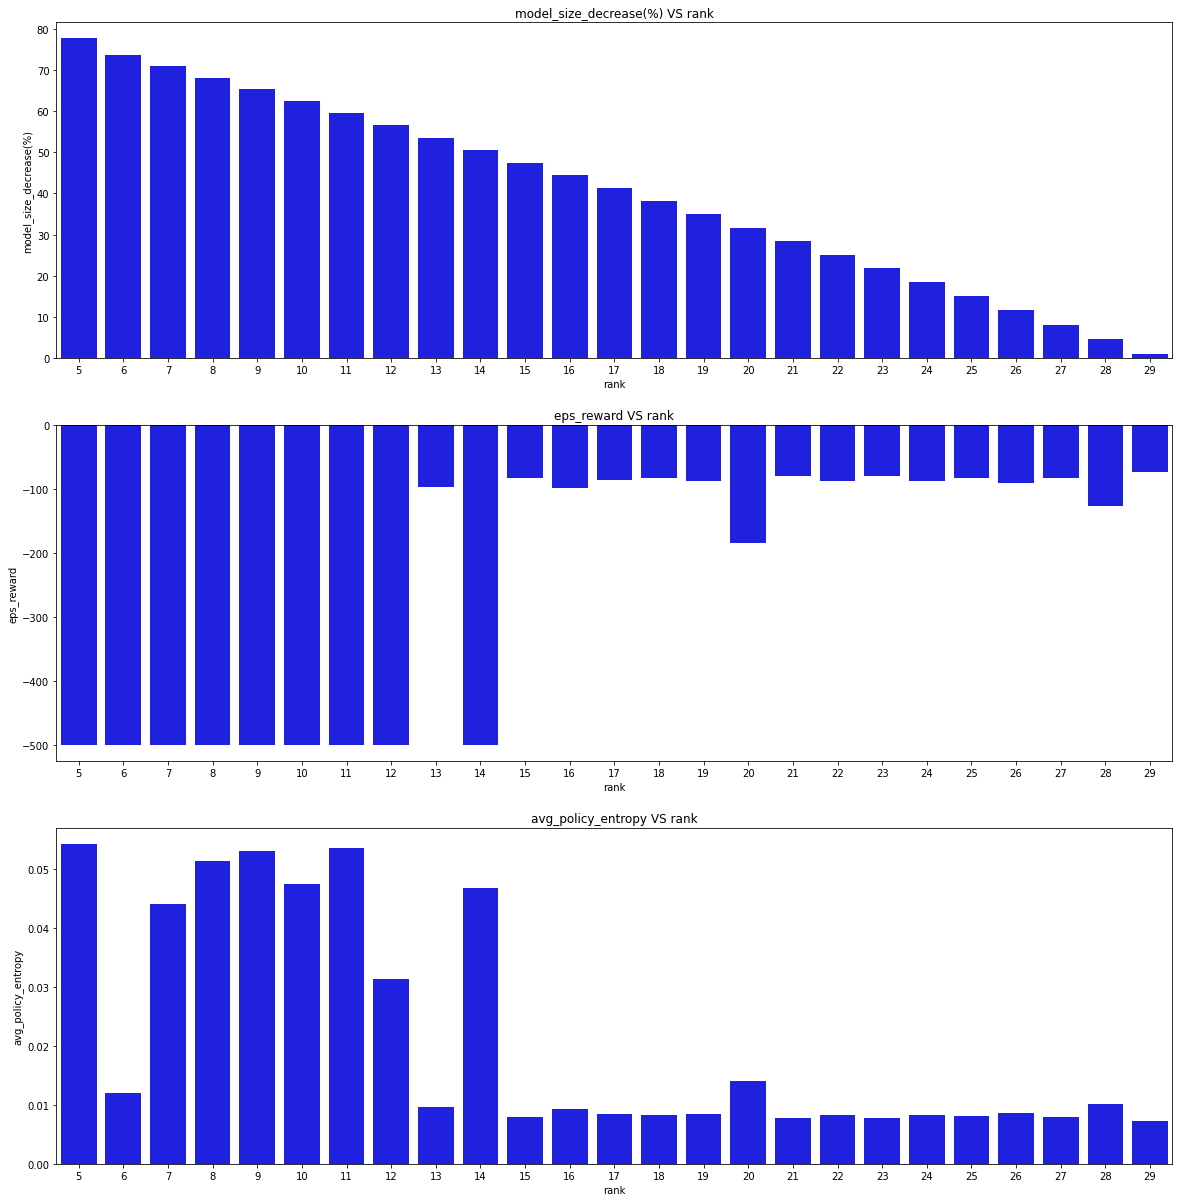

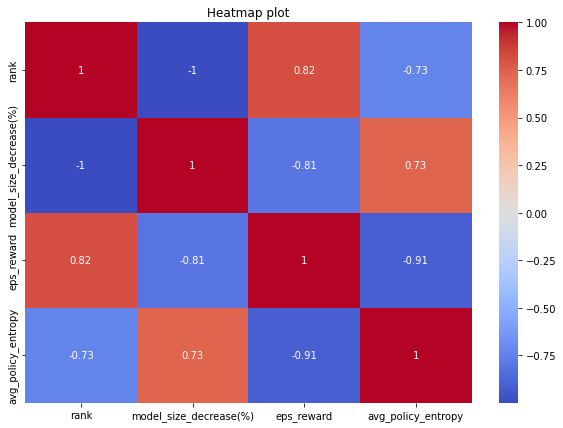

In [7]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []

for rank in tqdm(ranks):
    lra_sparse_policy_agent, p = low_rank_approximate_policy(sparse_policy_agent, rank)
    eps_reward, avg_policy_entropy = run_evaluation(
        gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), lra_sparse_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)

result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank", plot_type="bar", with_heatmap=True)
result.to_csv(os.path.join(results_dir, f"{env_name}_DQN_sparse_policy_decomposition.csv"), index=False)

In [8]:
del dense_policy_agent, sparse_policy_agent, lra_dense_policy_agent, lra_sparse_policy_agent, result
gc.collect()
torch.cuda.empty_cache()

# Low Rank Approximation of PPO Policies

#### **Evaluate Dense Policy**

In [9]:
dense_weights_filename = f"{env_name}_PPO_dense_policy_agent.pth.tar"
dense_policy_agent = PolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
dense_policy_agent.load_state_dict(torch.load(os.path.join("../params", dense_weights_filename), map_location=os.getenv("DEVICE")))

run_evaluation(gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), dense_policy_agent, verbose=True)

Evaluation reward of policy: -127.0
Average entropy of policy: 0.0091945


(-127.0, 0.009194518219694145)

#### **Evaluate Low Rank Approximated Dense Policy**

  0%|          | 0/25 [00:00<?, ?it/s]

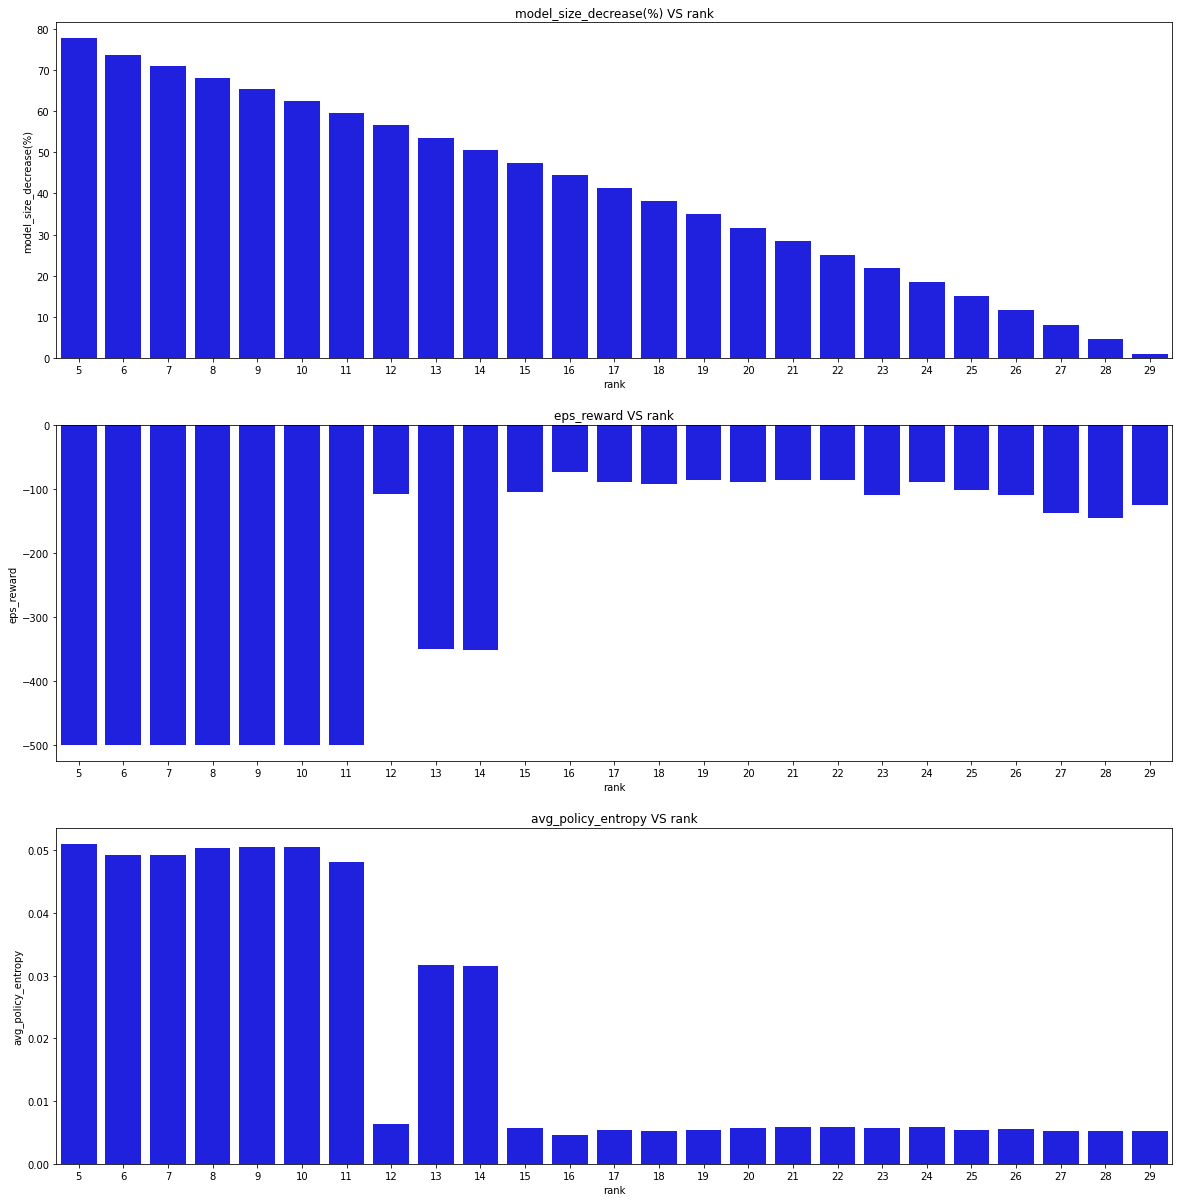

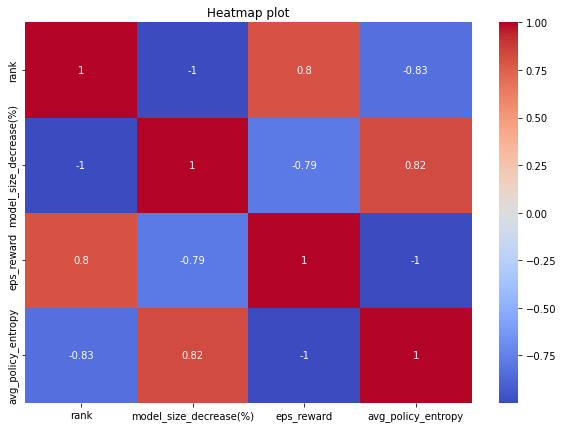

In [10]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []

for rank in tqdm(ranks):
    lra_dense_policy_agent, p = low_rank_approximate_policy(dense_policy_agent, rank)
    eps_reward, avg_policy_entropy = run_evaluation(
        gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), lra_dense_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    
result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank", plot_type="bar", with_heatmap=True)
result.to_csv(os.path.join(results_dir, f"{env_name}_PPO_dense_policy_decomposition.csv"), index=False)

#### **Evaluate Sparse Policy**

In [11]:
sparse_weights_filename = f"{env_name}_PPO_sparse_policy_agent.pth.tar"
sparse_policy_agent = SparsePolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
sparse_policy_agent.load_state_dict(torch.load(os.path.join("../params", sparse_weights_filename), map_location=os.getenv("DEVICE")))

result_df = run_evaluation(gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), sparse_policy_agent, verbose=True)

Evaluation reward of policy: -88.0
Average entropy of policy: 0.0079415


#### **Evaluate Low Rank Approximated Sparse Policy**

  0%|          | 0/25 [00:00<?, ?it/s]

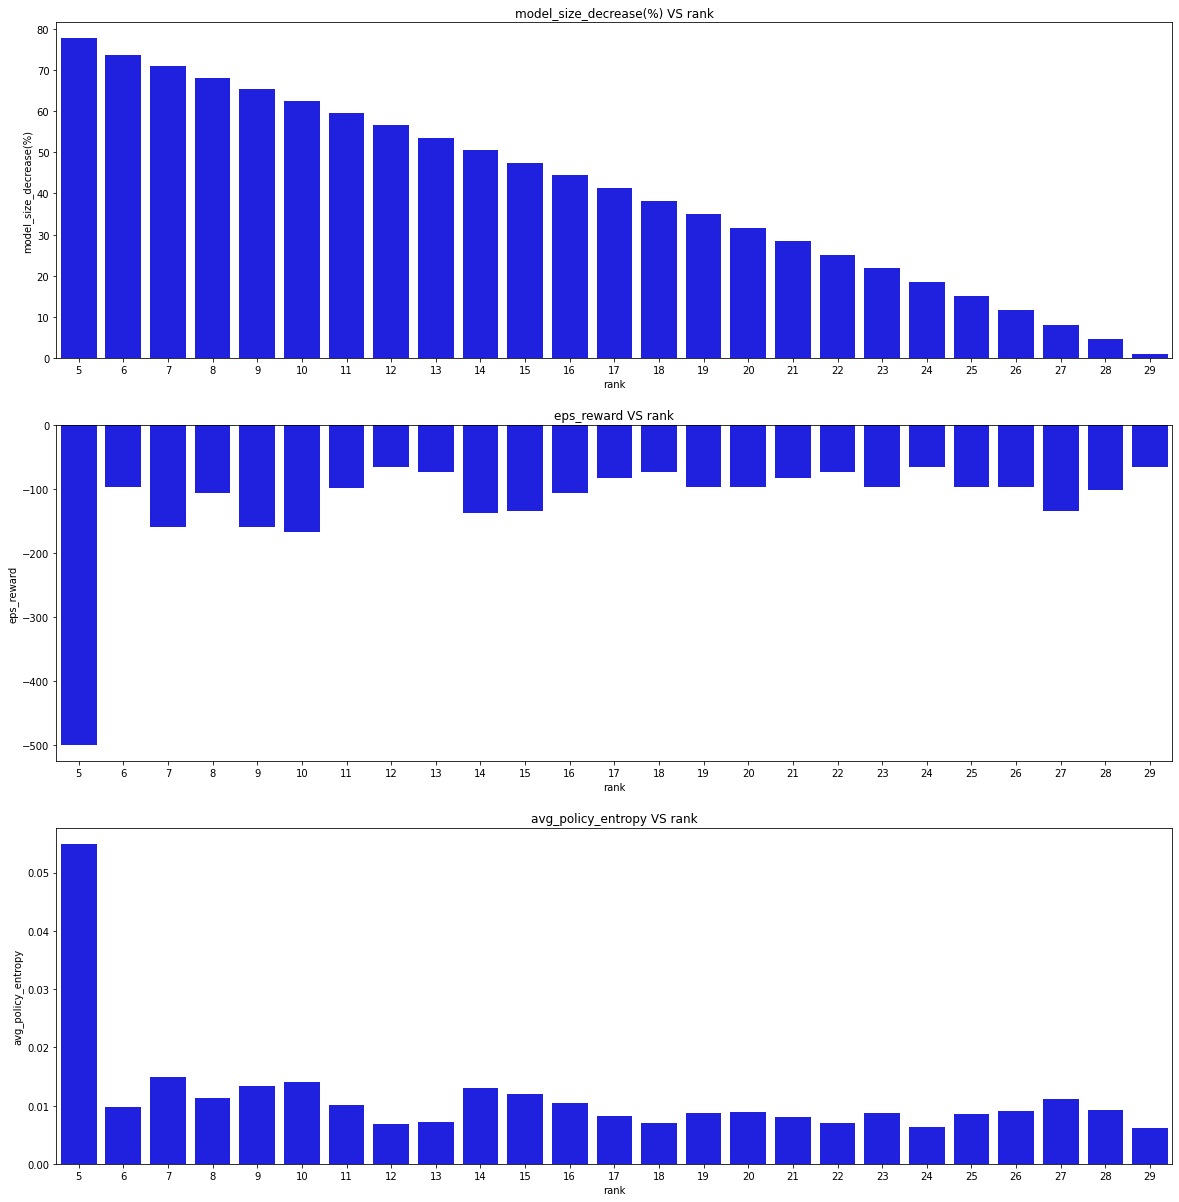

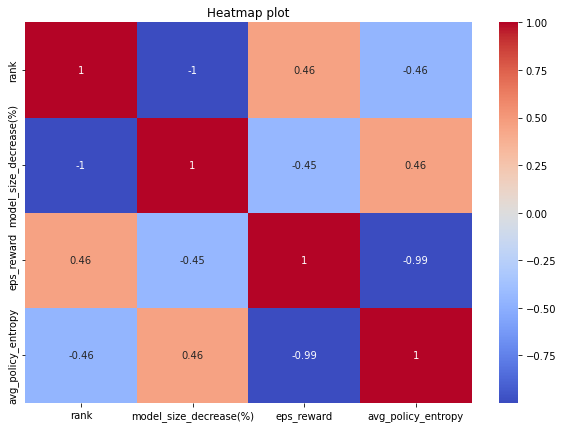

In [12]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []

for rank in tqdm(ranks):
    lra_sparse_policy_agent, p = low_rank_approximate_policy(sparse_policy_agent, rank)
    eps_reward, avg_policy_entropy = run_evaluation(
        gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), lra_sparse_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)

result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank", plot_type="bar", with_heatmap=True)
result.to_csv(os.path.join(results_dir, f"{env_name}_PPO_sparse_policy_decomposition.csv"), index=False)

In [13]:
del dense_policy_agent, sparse_policy_agent, lra_dense_policy_agent, lra_sparse_policy_agent, result
gc.collect()
torch.cuda.empty_cache()